# Рекомендательные системы книг в PySpark

**Цель:** сравнить популярность, поиск соседей средствами DataFrame и ALS, затем построить
гибрид с поддержкой холодного старта. Данные: Book-Crossing, опубликованные на Kaggle.
Ноль означает неявное взаимодействие, оценки 1–10 — явное предпочтение.
Ноутбук выполняется целиком командой `./run.ps1`; профиль `full` использует весь датасет.

Протокол фиксируется до обучения: разбиение по паре пользователь–книга 80/10/10,
выбор ALS по validation RMSE, однократная итоговая оценка на test. Временных меток здесь нет:
это случайная проверка восстановления оценок, а не имитация будущего потока.


In [1]:
import hashlib
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from pyspark import SparkContext
from pyspark.ml.recommendation import ALS
from pyspark.sql import SparkSession, Window, functions as F, types as T
from recommender import BookRecommender, als_candidates

PROFILE = os.environ.get('BOOKS_PROFILE', 'full')
assert PROFILE in {'smoke', 'full'}
SEED = 42
OUT = Path('artifacts') / PROFILE
OUT.mkdir(parents=True, exist_ok=True)
spark = (SparkSession.builder.appName('book-recommendations').master('local[6]')
         .config('spark.sql.shuffle.partitions', '12')
         .config('spark.default.parallelism', '12')
         .config('spark.ui.showConsoleProgress', 'false')
         .config('spark.sql.maxPlanStringLength', '8192')
         .config('spark.sql.adaptive.enabled', 'true').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
spark.sparkContext.setCheckpointDir(str((OUT / 'checkpoints').resolve()))
pd.set_option('display.max_colwidth', 80)
print({'profile': PROFILE, 'spark': spark.version, 'seed': SEED, 'parallelism': spark.sparkContext.defaultParallelism})
provenance = json.loads(Path('data/source.json').read_text(encoding='utf-8'))
display(provenance)

def save_table(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)
    display(frame)

def error_metrics(frame):
    row = frame.agg(F.count('*').alias('n'), F.sqrt(F.avg(F.pow(F.col('prediction') - F.col('rating'), 2))).alias('rmse'),
                    F.avg(F.abs(F.col('prediction') - F.col('rating'))).alias('mae')).first()
    return row.asDict()


{'profile': 'full', 'spark': '3.5.3', 'seed': 42, 'parallelism': 12}


{'url': 'https://www.kaggle.com/api/v1/datasets/download/arashnic/book-recommendation-dataset',
 'files': {'Books.csv': {'bytes': 73293635,
   'sha256': '8a406befc83452ab2dded8050dec47bccb6aa8110edb2512b62d8402f1a3d8dd'},
  'Ratings.csv': {'bytes': 22633892,
   'sha256': 'fbb819408aa8d42e7675200b26d48d66660b6e712bbd82585e5b564053d29de9'},
  'Users.csv': {'bytes': 11017438,
   'sha256': 'd82fe997ee9bfc455d0090b67d235694b82a9479d03e036665945ac9d30981bc'}}}

## 1. Чтение, качество данных и разведочный анализ

ISBN остаётся строкой: ведущие нули значимы. CSV читаются по заданной схеме, а не через
угадывание типов. Удаляются записи без корректного пользователя, ISBN или оценки 0–10.
Отсутствие названия не удаляет взаимодействие: для неизвестных ISBN создаётся строка каталога.
Возраст и место проживания не используются как признаки предпочтений: они неполны и для этой
работы не нужны. Некорректный год публикации превращается в null.


,ratings,books,users,invalid_rating_rows,duplicate_pairs,implicit_rows,explicit_pairs,pairs_without_book_metadata,pairs_without_user_metadata,invalid_or_unknown_ages
0,1149780,271360,278858,0,0,716109,433671,118641,0,112010


,rating,count
0,0.0,716109
1,1.0,1770
2,2.0,2759
3,3.0,5996
4,4.0,8904
5,5.0,50974
6,6.0,36924
7,7.0,76457
8,8.0,103736
9,9.0,67541


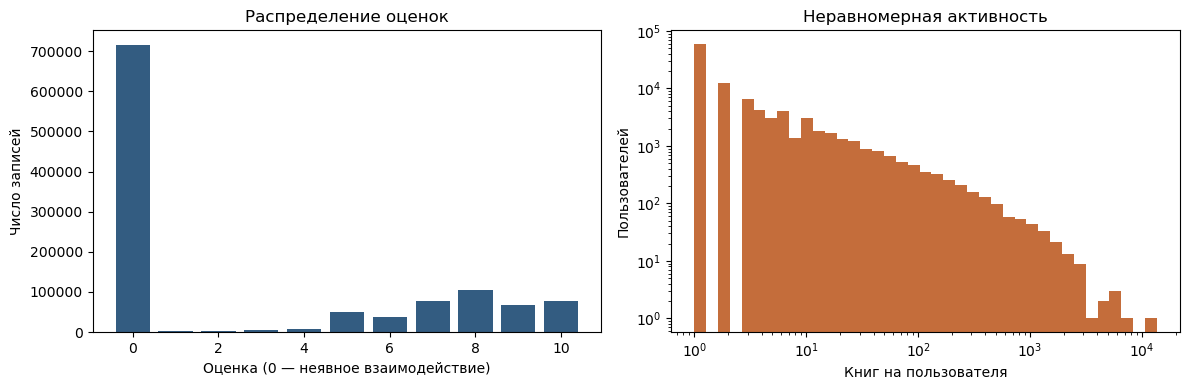

In [2]:
rating_schema = T.StructType([T.StructField('User-ID', T.IntegerType()), T.StructField('ISBN', T.StringType()), T.StructField('Book-Rating', T.DoubleType())])
book_columns = ['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']
book_schema = T.StructType([T.StructField(c, T.StringType()) for c in book_columns])
user_schema = T.StructType([T.StructField('User-ID', T.IntegerType()), T.StructField('Location', T.StringType()), T.StructField('Age', T.DoubleType())])
options = {'header': 'true', 'multiLine': 'true', 'quote': '"', 'escape': '"', 'mode': 'FAILFAST'}
raw_ratings = spark.read.options(**options).schema(rating_schema).csv('data/Ratings.csv')
raw_books = spark.read.options(**options).schema(book_schema).csv('data/Books.csv')
raw_users = spark.read.options(**options).schema(user_schema).csv('data/Users.csv')
counts = {'ratings': raw_ratings.count(), 'books': raw_books.count(), 'users': raw_users.count()}
assert counts == {'ratings': 1149780, 'books': 271360, 'users': 278858}, counts
ratings = raw_ratings.select(F.col('User-ID').alias('user_id'), F.upper(F.trim('ISBN')).alias('isbn'), F.col('Book-Rating').alias('rating'))
valid = ratings.filter(F.col('user_id').isNotNull() & (F.col('user_id') > 0) & (F.length('isbn') > 0) & F.col('rating').between(0, 10) & (F.col('rating') == F.floor('rating')))
pairs = valid.groupBy('user_id', 'isbn').agg(F.avg(F.when(F.col('rating') > 0, F.col('rating'))).alias('rating'), F.count('*').alias('records')).cache()
books = raw_books.select(F.upper(F.trim('ISBN')).alias('isbn'), F.trim('Book-Title').alias('title'),
                        F.trim('Book-Author').alias('author'), F.trim('Publisher').alias('publisher'),
                        F.col('Year-Of-Publication').cast('int').alias('year'))
books = books.filter(F.length('isbn') > 0).withColumn('year', F.when(F.col('year').between(1450, 2026), F.col('year')))
books = books.withColumn('completeness', sum(F.when(F.length(c) > 0, 1).otherwise(0) for c in ['title', 'author', 'publisher']))
books = (books.withColumn('choice', F.row_number().over(Window.partitionBy('isbn').orderBy(F.desc('completeness'), 'title', 'author', 'publisher', 'year')))
         .filter('choice = 1').drop('choice', 'completeness'))
quality = {**counts, 'invalid_rating_rows': counts['ratings'] - valid.count(),
           'duplicate_pairs': valid.count() - pairs.count(), 'implicit_rows': valid.filter('rating = 0').count(),
           'explicit_pairs': pairs.filter('rating is not null').count(),
           'pairs_without_book_metadata': pairs.join(books, 'isbn', 'left_anti').count(),
           'pairs_without_user_metadata': pairs.join(raw_users.select(F.col('User-ID').alias('user_id')), 'user_id', 'left_anti').count(),
           'invalid_or_unknown_ages': raw_users.filter(F.col('Age').isNull() | ~F.col('Age').between(5, 100)).count()}
save_table(pd.DataFrame([quality]), 'data_quality')
distribution = valid.groupBy('rating').count().orderBy('rating').toPandas()
save_table(distribution, 'rating_distribution')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(distribution.rating, distribution['count'], color='#335c81')
axes[0].set(xlabel='Оценка (0 — неявное взаимодействие)', ylabel='Число записей', title='Распределение оценок')
activity = pairs.groupBy('user_id').count().toPandas()['count']
axes[1].hist(activity, bins=np.logspace(0, np.log10(activity.max()), 40), color='#c46d3b')
axes[1].set(xscale='log', yscale='log', xlabel='Книг на пользователя', ylabel='Пользователей', title='Неравномерная активность')
fig.tight_layout()
fig.savefig(OUT / 'eda.png', dpi=160)
plt.show()


## 2. Идентификаторы и разбиение без утечки оценок

ALS требует целочисленные идентификаторы. Сортировка ISBN даёт воспроизводимое отображение,
которое сохраняется вместе с моделью. Наличие книги в каталоге не означает наличие обученного
фактора. Хеш пары вместе с seed назначает её ровно в одну выборку, включая нулевые взаимодействия.
Признаки популярности, соседство, история просмотренного и ALS используют только train.


In [3]:
all_isbns = pairs.select('isbn').union(books.select('isbn')).distinct()
mapping = all_isbns.withColumn('item_id', (F.row_number().over(Window.orderBy('isbn')) - 1).cast('int'))
catalog = (mapping.join(books, 'isbn', 'left').fillna({'title': 'название отсутствует', 'author': '', 'publisher': ''})
           .select('item_id', 'isbn', 'title', 'author', 'publisher', 'year').checkpoint(eager=True).cache())
data = pairs.join(catalog.select('isbn', 'item_id'), 'isbn').drop('records')
if PROFILE == 'smoke':
    active = pairs.filter('rating is not null').groupBy('user_id').count().orderBy(F.desc('count'), 'user_id').limit(400).select('user_id')
    data = data.join(active, 'user_id')
data = (data.withColumn('bucket', F.pmod(F.xxhash64('user_id', 'isbn', F.lit(SEED)), F.lit(100)))
        .withColumn('split', F.when(F.col('bucket') < 80, 'train').when(F.col('bucket') < 90, 'validation').otherwise('test'))
        .drop('bucket').checkpoint(eager=True).cache())
train_history = data.filter("split = 'train'").select('user_id', 'item_id').cache()
train = data.filter("split = 'train' and rating is not null").select('user_id', 'item_id', 'rating').cache()
validation = data.filter("split = 'validation' and rating is not null").select('user_id', 'item_id', 'rating').cache()
test = data.filter("split = 'test' and rating is not null").select('user_id', 'item_id', 'rating').cache()
split_table = data.groupBy('split').agg(F.count('*').alias('interactions'), F.count('rating').alias('explicit_ratings'),
                                       F.countDistinct('user_id').alias('users'), F.countDistinct('item_id').alias('items')).toPandas()
save_table(split_table, 'split')
assert data.count() == data.select('user_id', 'item_id').distinct().count()
assert train.join(test, ['user_id', 'item_id']).count() == 0
assert train.join(validation, ['user_id', 'item_id']).count() == 0
assert test.join(validation, ['user_id', 'item_id']).count() == 0
assert catalog.select('item_id').distinct().count() == catalog.count()
global_mean = train.agg(F.avg('rating')).first()[0]
explicit_stats = train.groupBy('item_id').agg(F.count('*').alias('votes'), F.sum('rating').alias('rating_sum'))
popularity = (train_history.groupBy('item_id').agg(F.countDistinct('user_id').alias('readers'))
              .join(explicit_stats, 'item_id', 'left').fillna({'votes': 0, 'rating_sum': 0.0})
              .withColumn('smoothed_mean', (F.col('rating_sum') + 20 * global_mean) / (F.col('votes') + 20))
              .select('item_id', 'readers', 'smoothed_mean').cache())


,split,interactions,explicit_ratings,users,items
0,validation,114843,43510,27783,70450
1,train,920167,346700,92986,298103
2,test,114770,43461,27685,70582


## 3. Базовая эвристика: популярное

Критерий — число уникальных пользователей с любым train-взаимодействием. При равенстве
используется сглаженная средняя явная оценка, затем ISBN. Сглаживание с 20 виртуальными
оценками, равными train-среднему, не позволяет одной десятке доминировать в ничьей.
Минусы: нет персонализации, усиливается преимущество хитов, новые книги не набирают историю;
взаимодействие не гарантирует симпатию, а временную актуальность без дат оценить нельзя.


In [4]:
popular_books = popularity.join(catalog, 'item_id').orderBy(F.desc('readers'), F.desc('smoothed_mean'), 'isbn')
save_table(popular_books.select('isbn', 'title', 'author', 'readers', 'smoothed_mean').limit(10).toPandas(), 'popular_top10')


,isbn,title,author,readers,smoothed_mean
0,0971880107,Wild Animus,Rich Shapero,2020,4.525089
1,0316666343,The Lovely Bones: A Novel,Alice Sebold,1050,8.146376
2,0385504209,The Da Vinci Code,Dan Brown,703,8.353679
3,0060928336,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,588,7.853295
4,0312195516,The Red Tent (Bestselling Backlist),Anita Diamant,572,8.102066
5,0679781587,название отсутствует,,533,8.407514
6,044023722X,A Painted House,John Grisham,512,7.343262
7,0142001740,The Secret Life of Bees,Sue Monk Kidd,502,8.354979
8,067976402X,Snow Falling on Cedars,David Guterson,489,7.828368
9,0671027360,Angels &amp; Demons,Dan Brown,471,8.072023


## 4. Коллаборативная фильтрация без ML: три соседа

Сравниваем только общие явно оценённые книги. Требуем не менее пяти совпадений.
Сходство `n / (n + 10) × (1 − MAE / 9)` лежит в [0, 1]: первая часть штрафует малую опору,
вторая учитывает близость оценок на шкале 1–10. Это выбранная эвристика, не обученная модель.
Соседи упорядочиваются по сходству, числу общих книг, MAE и ID. Рекомендуются их оценки ≥8;
все train-взаимодействия пользователя, в том числе нули, исключаются.

В Spark ML нет штатного user-kNN рекомендателя. Точный поиск соседей для всех пользователей
создаёт большое число пар, shuffle и дорогие пересчёты при обновлении. ALS представляет
предпочтения компактными факторами. Это объясняет инженерные преимущества ALS, но не означает,
что поиск соседей невозможен: существуют приближённый поиск и ограничение кандидатов.


In [5]:
active_users = train.groupBy('user_id').count().orderBy(F.desc('count'), 'user_id').limit(50).collect()
for active_row in active_users:
    target_id = active_row.user_id
    target = train.filter(F.col('user_id') == target_id).select('item_id', F.col('rating').alias('target_rating'))
    overlaps = train.filter(F.col('user_id') != target_id).join(target, 'item_id')
    neighbors = (overlaps.groupBy('user_id').agg(F.count('*').alias('common'), F.avg(F.abs(F.col('rating') - F.col('target_rating'))).alias('mae'))
                 .filter('common >= 5').withColumn('similarity', F.col('common') / (F.col('common') + 10) * (1 - F.col('mae') / 9))
                 .orderBy(F.desc('similarity'), F.desc('common'), 'mae', 'user_id').limit(3).cache())
    if neighbors.count() == 3:
        break
    neighbors.unpersist()
assert neighbors.count() == 3
print('целевой пользователь:', target_id)
save_table(neighbors.toPandas(), 'neighbors')
neighbor_recs = (train.join(neighbors.select('user_id', 'similarity'), 'user_id').filter('rating >= 8')
                 .join(train_history.filter(F.col('user_id') == target_id).select('item_id'), 'item_id', 'left_anti')
                 .groupBy('item_id').agg((F.sum(F.col('rating') * F.col('similarity')) / F.sum('similarity')).alias('score'),
                                       F.countDistinct('user_id').alias('support'))
                 .join(catalog, 'item_id').orderBy(F.desc('score'), F.desc('support'), 'isbn'))
save_table(neighbor_recs.select('isbn', 'title', 'author', 'score', 'support').limit(10).toPandas(), 'neighbor_recommendations')


целевой пользователь: 11676


,user_id,common,mae,similarity
0,98391,159,1.654088,0.767916
1,60244,67,1.268657,0.747475
2,16795,115,1.930435,0.722667


,isbn,title,author,score,support
0,0060002077,A Gentleman's Honor,Stephanie Laurens,10.0,1
1,0060004746,"Murder Walks the Plank : A Death on Demand Mystery (Hart, Carolyn G)",Carolyn Hart,10.0,1
2,0060006617,A Perfect Bride,Samantha James,10.0,1
3,0060013133,"Going Postal : A Novel of Discworld (Pratchett, Terry)",Terry Pratchett,10.0,1
4,006001315X,"Monstrous Regiment (Pratchett, Terry)",Terry Pratchett,10.0,1
5,0060081635,The Last of the Honky-tonk Angels : A Novel,Marsha Moyer,10.0,1
6,006009298X,Temptation of a Proper Governess,Cathy Maxwell,10.0,1
7,0060097701,The Crimson Lady,Mary Reed McCall,10.0,1
8,0060198303,"The Burglar on the Prowl (Block, Lawrence)",Lawrence Block,10.0,1
9,0060199261,The Bronze Horseman: A Novel,Paullina Simons,10.0,1


## 5. Обучение ALS и выбор гиперпараметров

Явный ALS приближает матрицу оценок произведением факторов пользователей и книг, попеременно
оптимизируя их с регуляризацией. `rank` — размерность факторов, `regParam` — сила регуляризации.
`nonnegative=True` ограничивает факторы неотрицательными значениями; оценки не обязаны лежать в 1–10.
`implicitPrefs=False`: нули не подаются как отрицательные оценки. Девять вариантов сравниваются
на одной validation-выборке; выбор по raw RMSE, затем меньшему rank и большей регуляризации.
После выбора модель не переобучается на validation: определение истории и тестового протокола
остаётся неизменным. `nan` позволяет честно посчитать покрытие, а не скрыть холодные пары.


In [6]:
grid = [(r, reg) for r in [10, 20, 40] for reg in [0.01, 0.1, 1.0]] if PROFILE == 'full' else [(5, 0.1)]
trials = []
best_key, best_model = None, None
for rank, regularization in grid:
    started = time.monotonic()
    estimator = ALS(userCol='user_id', itemCol='item_id', ratingCol='rating', rank=rank,
                    regParam=regularization, maxIter=15 if PROFILE == 'full' else 3, seed=SEED,
                    nonnegative=True, implicitPrefs=False, coldStartStrategy='nan',
                    numUserBlocks=6, numItemBlocks=6, checkpointInterval=2)
    model = estimator.fit(train)
    scored = model.transform(validation).cache()
    warm = scored.filter(~F.isnan('prediction') & F.col('prediction').isNotNull())
    metrics = error_metrics(warm)
    trial = {'rank': rank, 'regParam': regularization, **metrics,
             'coverage': metrics['n'] / validation.count(), 'seconds': time.monotonic() - started}
    trials.append(trial)
    key = (metrics['rmse'], rank, -regularization)
    if best_key is None or key < best_key:
        best_key, best_model = key, model
        best_model.write().overwrite().save(str((OUT / 'inference/model').resolve()))
    scored.unpersist()
    print('ALS trial', json.dumps(trial), flush=True)
save_table(pd.DataFrame(trials), 'als_search')
print('выбрано:', {'rank': best_model.rank, 'regParam': -best_key[2], 'validation_rmse': best_key[0]})


ALS trial {"rank": 10, "regParam": 0.01, "n": 25711, "rmse": 3.3843446708352616, "mae": 2.5288669501678074, "coverage": 0.5909216272121351, "seconds": 26.31945966500001}


ALS trial {"rank": 10, "regParam": 0.1, "n": 25711, "rmse": 2.415715018165529, "mae": 1.8734857602488524, "coverage": 0.5909216272121351, "seconds": 19.079948743000017}


ALS trial {"rank": 10, "regParam": 1.0, "n": 25711, "rmse": 2.1897983229359927, "mae": 1.763144790484312, "coverage": 0.5909216272121351, "seconds": 17.40781166299999}


ALS trial {"rank": 20, "regParam": 0.01, "n": 25711, "rmse": 3.1783152939646593, "mae": 2.490734712490334, "coverage": 0.5909216272121351, "seconds": 33.08547986299999}


ALS trial {"rank": 20, "regParam": 0.1, "n": 25711, "rmse": 2.408440602910613, "mae": 1.8891329253776656, "coverage": 0.5909216272121351, "seconds": 27.606767858000012}


...

ALS trial {"rank": 40, "regParam": 0.01, "n": 25711, "rmse": 3.2288771709810367, "mae": 2.582324324167239, "coverage": 0.5909216272121351, "seconds": 63.46381034500001}


ALS trial {"rank": 40, "regParam": 0.1, "n": 25711, "rmse": 2.3969662411138932, "mae": 1.8841116909384101, "coverage": 0.5909216272121351, "seconds": 44.27132439000002}


ALS trial {"rank": 40, "regParam": 1.0, "n": 25711, "rmse": 2.200474413324305, "mae": 1.772327075573686, "coverage": 0.5909216272121351, "seconds": 35.31311969799998}


,rank,regParam,n,rmse,mae,coverage,seconds
0,10,0.01,25711,3.384345,2.528867,0.590922,26.319460
1,10,0.10,25711,2.415715,1.873486,0.590922,19.079949
2,10,1.00,25711,2.189798,1.763145,0.590922,17.407812
3,20,0.01,25711,3.178315,2.490735,0.590922,33.085480
4,20,0.10,25711,2.408441,1.889133,0.590922,27.606768
5,20,1.00,25711,2.196704,1.769399,0.590922,22.146624
6,40,0.01,25711,3.228877,2.582324,0.590922,63.463810
7,40,0.10,25711,2.396966,1.884112,0.590922,44.271324
8,40,1.00,25711,2.200474,1.772327,0.590922,35.313120


выбрано: {'rank': 10, 'regParam': 1.0, 'validation_rmse': 2.1897983229359927}


## 6. Итоговый тест: ошибки и покрытие

RMSE сильнее штрафует большие ошибки оценки; MAE легче интерпретировать в баллах.
Обе метрики описывают восстановление явных оценок, но не порядок выдачи, разнообразие или
удовлетворённость. Сравниваем ALS, общее среднее и сглаженное среднее книги на **одних и тех же
тёплых test-парах**. Отдельно показываем долю всех пар, на которых ALS способен предсказать.
Clipped RMSE приводится отдельно и не используется для выбора модели.


In [7]:
user_factors = best_model.userFactors.select(F.col('id').alias('user_id'), F.lit(True).alias('known_user'))
item_factors = best_model.itemFactors.select(F.col('id').alias('item_id'), F.lit(True).alias('known_item'))
test_scored = (best_model.transform(test).join(user_factors, 'user_id', 'left').join(item_factors, 'item_id', 'left')
               .fillna({'known_user': False, 'known_item': False}).cache())
coverage = test_scored.groupBy('known_user', 'known_item').count().orderBy('known_user', 'known_item').toPandas()
coverage['share'] = coverage['count'] / test.count()
save_table(coverage, 'test_coverage')
test_warm = test_scored.filter('known_user and known_item').cache()
assert test_warm.filter(F.isnan('prediction')).count() == 0
test_metrics = [{'model': 'als_raw', **error_metrics(test_warm)}]
test_metrics.append({'model': 'als_clipped_1_10', **error_metrics(test_warm.withColumn('prediction', F.greatest(F.lit(1.0), F.least(F.lit(10.0), F.col('prediction')))))})
test_metrics.append({'model': 'global_mean', **error_metrics(test_warm.withColumn('prediction', F.lit(global_mean)))})
test_metrics.append({'model': 'item_mean_smoothed', **error_metrics(test_warm.join(popularity, 'item_id').withColumn('prediction', F.col('smoothed_mean')))})
save_table(pd.DataFrame(test_metrics), 'test_metrics')
save_table(test_warm.join(catalog, 'item_id').orderBy('user_id', 'isbn').select('user_id', 'isbn', 'title', 'author', 'rating', 'prediction').limit(10).toPandas(), 'prediction_examples')


,known_user,known_item,count,share
0,False,False,1500,0.034514
1,False,True,3537,0.081383
2,True,False,12772,0.293873
3,True,True,25652,0.590230


,model,n,rmse,mae
0,als_raw,25652,2.194416,1.760895
1,als_clipped_1_10,25652,2.192956,1.759803
2,global_mean,25652,1.806502,1.464442
3,item_mean_smoothed,25652,1.767331,1.417354


,user_id,isbn,title,author,rating,prediction
0,8,0002005018,Clara Callan,Richard Bruce Wright,5.0,5.827025
1,17,0553264990,Bant/Spec.Last of the Breed,Louis L'Amour,5.0,4.422844
2,183,8440630794,Cuentos del Planeta Tierra,Arthur C. Clarke,7.0,5.714611
3,183,9722113747,название отсутствует,,9.0,6.251794
4,228,0385337639,Crow Lake (Today Show Book Club #7),Mary Lawson,7.0,7.559395
5,232,0486284735,Pride and Prejudice (Dover Thrift Editions),Jane Austen,8.0,6.258195
6,242,3150000335,Kabale Und Liebe,Schiller,10.0,6.221252
7,242,3498020862,Die Korrekturen.,Jonathan Franzen,8.0,3.206140
8,243,0385720106,A Map of the World,Jane Hamilton,7.0,6.524825
9,254,0060934700,Smoke and Mirrors: Short Fictions and Illusions,Neil Gaiman,9.0,6.771336


## 7. Качество ранжирования на полном каталоге факторов

Фиксируем до 1000 пользователей с фактором ALS и хотя бы одной релевантной test-книгой
(оценка ≥8), которая также имеет фактор. Отбор детерминирован хешем ID. Это условная оценка
тёплого сценария, не качество для всех пользователей. Полноту и NDCG считаем по всем доступным
кандидатам модели, без сэмплирования отрицательных примеров. Неоценённые книги не считаются
доказанно плохими: offline-метрики на наблюдаемых оценках имеют смещение отбора.

Из выдачи удаляется train-история. Начальные 50 кандидатов ALS расширяются вдвое, если после
фильтрации их недостаточно. Для популярных книг используется тот же каталог факторов,
та же история, тот же набор пользователей и релевантных книг.


In [8]:
relevant = test.filter('rating >= 8').join(user_factors.select('user_id'), 'user_id').join(item_factors.select('item_id'), 'item_id')
cohort = relevant.select('user_id').distinct().orderBy(F.xxhash64('user_id', F.lit(SEED)), 'user_id').limit(1000 if PROFILE == 'full' else 20).cache()
truth = relevant.join(cohort, 'user_id').select('user_id', 'item_id').cache()
factor_count = item_factors.count()
als_top = als_candidates(best_model, cohort, train_history, 10, factor_count)
max_seen = train_history.join(cohort, 'user_id').groupBy('user_id').count().agg(F.max('count')).first()[0]
pop_pool = (popularity.join(item_factors.select('item_id'), 'item_id').join(catalog.select('item_id', 'isbn'), 'item_id')
            .orderBy(F.desc('readers'), F.desc('smoothed_mean'), 'isbn').limit(int(max_seen) + 10))
pop_top = (cohort.crossJoin(pop_pool).join(train_history, ['user_id', 'item_id'], 'left_anti')
           .withColumn('rank', F.row_number().over(Window.partitionBy('user_id').orderBy(F.desc('readers'), F.desc('smoothed_mean'), 'isbn')))
           .filter('rank <= 10').select('user_id', 'item_id', 'rank').cache())

def ranking_metrics(recommendations, relevant_pairs, users, catalog_size, k=10):
    hits = recommendations.join(relevant_pairs.withColumn('hit', F.lit(1.0)), ['user_id', 'item_id'], 'left').fillna({'hit': 0.0})
    observed = hits.groupBy('user_id').agg(F.sum('hit').alias('hits'), F.sum(F.col('hit') / F.log2(F.col('rank') + 1)).alias('dcg'))
    ideal = relevant_pairs.groupBy('user_id').count().withColumn('idcg', F.aggregate(F.sequence(F.lit(1), F.least(F.col('count').cast('int'), F.lit(k))), F.lit(0.0), lambda acc, i: acc + 1.0 / F.log2(i + 1)))
    per_user = users.join(ideal, 'user_id').join(observed, 'user_id', 'left').fillna({'hits': 0.0, 'dcg': 0.0})
    result = per_user.agg(F.avg(F.col('hits') / F.col('count')).alias('recall_at_10'), F.avg(F.col('dcg') / F.col('idcg')).alias('ndcg_at_10')).first().asDict()
    result.update(users=users.count(), catalog_coverage=recommendations.select('item_id').distinct().count() / catalog_size)
    return result

ranking = [{'model': 'als', **ranking_metrics(als_top, truth, cohort, factor_count)},
           {'model': 'popular', **ranking_metrics(pop_top, truth, cohort, factor_count)}]
save_table(pd.DataFrame(ranking), 'ranking_metrics')
truth.orderBy('user_id', 'item_id').toPandas().to_csv(OUT / 'ranking_truth.csv', index=False)
als_top.orderBy('user_id', 'rank').toPandas().to_csv(OUT / 'ranking_als_top10.csv', index=False)
pop_top.orderBy('user_id', 'rank').toPandas().to_csv(OUT / 'ranking_popular_top10.csv', index=False)
assert als_top.join(train_history, ['user_id', 'item_id']).count() == 0
assert als_top.groupBy('user_id', 'item_id').count().filter('count > 1').count() == 0
demo_export = als_top.filter('rank <= 3').join(catalog, 'item_id').select('user_id', 'rank', 'isbn', 'title', 'author', 'score')
demo_export.orderBy('user_id', 'rank').toPandas().to_csv(OUT / 'recommendations_1000_users.csv', index=False)
print('пользователей в демонстрационной выгрузке:', cohort.count())


,model,recall_at_10,ndcg_at_10,users,catalog_coverage
0,als,0.000000,0.00000,1000,0.001986
1,popular,0.017911,0.01012,1000,0.000145


пользователей в демонстрационной выгрузке: 1000


## 8. Холодный старт и гибрид

Неизвестный фактор пользователя или книги даёт NaN. `coldStartStrategy="drop"` только
скрывает такие строки и не решает проблему. Одна явная train-оценка математически достаточна
для фактора пользователя, но не гарантирует хорошую персонализацию. Один ноль не участвует
в нашем явном ALS. Новая оценка после обучения сама по себе не обновляет сохранённую модель.

Гибрид: тёплый пользователь получает ALS; холодный без предпочтений — популярное; холодный
с выбранными ISBN — совпадение автора (+2) и издателя (+1), затем популярность при равенстве.
Остаток списка заполняется популярным. История и выбранные ISBN всегда исключаются.
У контентного пути есть ограничения: издатель слишком широкий сигнал, а жанров в данных нет.
Книги без ALS-фактора доступны контентному пути; отдельный пример показывает такие книги.
Отсутствие фактора не доказывает, что книга недавно опубликована.


In [9]:
context = BookRecommender(spark, best_model, catalog, train_history, popularity)
single_id = train.groupBy('user_id').count().filter('count = 1').orderBy('user_id').first()
cold_id = 2147483647
assert data.filter(F.col('user_id') == cold_id).count() == 0
known_item = best_model.itemFactors.select('id').orderBy('id').first()[0]
cold_item = catalog.join(item_factors.select('item_id'), 'item_id', 'left_anti').orderBy('item_id').first().item_id
probes = [(target_id, known_item), (cold_id, known_item), (target_id, cold_item)]
if single_id is not None:
    probes.append((single_id.user_id, known_item))
probe_data = spark.createDataFrame(probes, 'user_id int, item_id int')
probe_predictions = best_model.transform(probe_data)
save_table(probe_predictions.toPandas(), 'cold_start_predictions')
assert probe_predictions.filter(F.col('user_id') == cold_id).filter(F.isnan('prediction')).count() == 1
print('nan сохраняет строки:', probe_predictions.count(), '; drop сохраняет:', best_model.copy({best_model.coldStartStrategy: 'drop'}).transform(probe_data).count())
liked = [r.isbn for r in train.filter(F.col('user_id') == target_id).orderBy(F.desc('rating'), 'item_id').limit(3).join(catalog, 'item_id').select('isbn').collect()]
examples = {}
for name, uid, preferences in [('warm', target_id, None), ('cold', cold_id, None), ('onboarding', cold_id, liked)]:
    recommendations = context.recommend(uid, 3, preferences)
    assert len(recommendations) == 3 and recommendations.isbn.nunique() == 3
    assert not set(recommendations.isbn).intersection(preferences or [])
    examples[name] = recommendations
    print(name, uid)
    save_table(recommendations, f'hybrid_{name}')
cold_content = context.recommend(cold_id, 3, liked, cold_items_only=True)
save_table(cold_content, 'cold_book_content')
if single_id is not None:
    save_table(context.recommend(single_id.user_id, 3), 'single_rating_user')


,user_id,item_id,prediction
0,11676,0,NaN
1,11676,1,4.139571
2,2147483647,1,NaN
3,9,1,3.235664


nan сохраняет строки: 4 ; drop сохраняет: 2


warm 11676


,rank,item_id,isbn,title,author,score,source,reason,readers,smoothed_mean
0,1,279408,1891620614,The Global Me: New Cosmopolitans and the Competitive Edge: Picking Globalism...,G. Pascal Zachary,10.404151,als,"факторы пользователя и книги, изученные на обучении",1,7.717588
1,2,163484,0674194241,Deaf in America: Voices from a Culture,Carol Padden,10.366343,als,"факторы пользователя и книги, изученные на обучении",3,7.717588
2,3,13586,0062772635,Access Sydney,Access Press,10.236541,als,"факторы пользователя и книги, изученные на обучении",1,7.717588


cold 2147483647


,rank,item_id,isbn,title,author,score,source,reason,readers,smoothed_mean
0,1,247880,0971880107,Wild Animus,Rich Shapero,2020.0,popular,популярность по уникальным читателям обучающей выборки,2020,4.525089
1,2,47452,0316666343,The Lovely Bones: A Novel,Alice Sebold,1050.0,popular,популярность по уникальным читателям обучающей выборки,1050,8.146376
2,3,83496,0385504209,The Da Vinci Code,Dan Brown,703.0,popular,популярность по уникальным читателям обучающей выборки,703,8.353679


onboarding 2147483647


,rank,item_id,isbn,title,author,score,source,reason,readers,smoothed_mean
0,1,567,0002256886,Araby,Gretta Mulrooney,2.0,content,совпадение автора (+2) и/или издателя (+1),3,7.603467
1,2,2320,0006551823,MARBLE HEART,Gretta Mulrooney,2.0,content,совпадение автора (+2) и/или издателя (+1),1,7.622349
2,3,2234,0006547834,Miss Smillas Feeling for Snow,Peter Hoeg,1.0,content,совпадение автора (+2) и/или издателя (+1),28,7.814667


,rank,item_id,isbn,title,author,score,source,reason,readers,smoothed_mean
0,1,567,0002256886,Araby,Gretta Mulrooney,2.0,content,совпадение автора (+2) и/или издателя (+1),3,7.603467
1,2,588,000225851X,Godless in Eden: A Book of Essays,Fay Weldon,1.0,content,совпадение автора (+2) и/или издателя (+1),4,7.603467
2,3,2264,0006550231,Statement,Brian Moore,1.0,content,совпадение автора (+2) и/или издателя (+1),4,7.603467


,rank,item_id,isbn,title,author,score,source,reason,readers,smoothed_mean
0,1,209588,0812550544,Haunted America (Haunted America),Michael Norman,8.138082,als,"факторы пользователя и книги, изученные на обучении",5,7.717588
1,2,163484,0674194241,Deaf in America: Voices from a Culture,Carol Padden,8.106101,als,"факторы пользователя и книги, изученные на обучении",3,7.717588
2,3,279408,1891620614,The Global Me: New Cosmopolitans and the Competitive Edge: Picking Globalism...,G. Pascal Zachary,8.071830,als,"факторы пользователя и книги, изученные на обучении",1,7.717588


## 9. Проверки логики и сохранение для последующих запросов

Проверяем метрики на маленьком примере с известным ответом: при двух релевантных книгах
и одном попадании на первой позиции Recall = 1/2, NDCG = 1/(1+1/log₂3).
Сохраняются модель, отображение ISBN, метаданные, история train и популярность. Этого достаточно
для запросов после перезапуска; исходные CSV при инференсе не требуются.


In [10]:
toy_users = spark.createDataFrame([(1,)], 'user_id int')
toy_truth = spark.createDataFrame([(1, 10), (1, 20)], 'user_id int, item_id int')
toy_recs = spark.createDataFrame([(1, 10, 1), (1, 30, 2)], 'user_id int, item_id int, rank int')
toy_metrics = ranking_metrics(toy_recs, toy_truth, toy_users, 4)
assert abs(toy_metrics['recall_at_10'] - 0.5) < 1e-12
assert abs(toy_metrics['ndcg_at_10'] - 1 / (1 + 1 / np.log2(3))) < 1e-12
toy_overlap = spark.createDataFrame([(10, 0.0), (5, 9.0)], 'common int, mae double')
toy_similarity = toy_overlap.select((F.col('common') / (F.col('common') + 10) * (1 - F.col('mae') / 9)).alias('similarity')).collect()
assert [r.similarity for r in toy_similarity] == [0.5, 0.0]
class ToyModel:
    def recommendForUserSubset(self, users, size):
        return spark.createDataFrame([(7, [(i, float(100 - i)) for i in range(size)])],
                                     'user_id int, recommendations array<struct<item_id:int,rating:float>>')

toy_history = spark.createDataFrame([(7, i) for i in range(55)], 'user_id int, item_id int')
toy_candidates = als_candidates(ToyModel(), spark.createDataFrame([(7,)], 'user_id int'), toy_history, 3, 60)
assert [r.item_id for r in toy_candidates.orderBy('rank').collect()] == [55, 56, 57]
toy_candidates.unpersist()
warm_seen = {r.item_id for r in train_history.filter(F.col('user_id') == target_id).collect()}
assert not warm_seen.intersection(examples['warm'].item_id)
assert set(examples['cold'].source) == {'popular'}
assert 'content' in set(examples['onboarding'].source)
inference = OUT / 'inference'
for frame, name, partitions in [(catalog, 'catalog', 4), (train_history, 'history', 8), (popularity, 'popularity', 4)]:
    frame.coalesce(partitions).write.mode('overwrite').parquet(str((inference / name).resolve()))
manifest = {'profile': PROFILE, 'spark': spark.version, 'seed': SEED, 'rank': best_model.rank,
            'regParam': -best_key[2], 'target_id': target_id, 'cold_id': cold_id,
            'liked_isbns': liked, 'single_rating_user': None if single_id is None else single_id.user_id,
            'validation_rmse': best_key[0], 'test_metrics': test_metrics, 'ranking_metrics': ranking,
            'catalog_items': catalog.count(), 'factor_items': factor_count, 'factor_users': user_factors.count()}
(inference / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
reload_sample = test_warm.orderBy('user_id', 'item_id').limit(100).select('user_id', 'item_id', 'prediction').toPandas()
reload_sample.to_json(OUT / 'reload_sample.json', orient='records', indent=2)
print('проверки пройдены; артефакты сохранены:', str(inference))


проверки пройдены; артефакты сохранены: artifacts/full/inference


## 10. Проверка после остановки исходной Spark-сессии

Отдельный Python-процесс загружает модель и сопровождающие таблицы с диска, повторяет
100 предсказаний с допуском 1e−6, проверяет маршруты ALS/популярность/контент и исключение истории.
Это проверка восстановления, а не повторное обучение. После неё публичная функция доступна
в новом ядре: `from recommender import recommend_books; recommend_books(user_id=12345, k=3)`.


In [11]:
gateway_process = spark.sparkContext._gateway.proc
spark.stop()
# остановка sparkcontext не завершает jvm; освобождаем её память перед независимой проверкой
if gateway_process is not None:
    gateway_process.terminate()
    gateway_process.wait(timeout=30)
SparkContext._gateway = None
SparkContext._jvm = None
environment = os.environ.copy()
for name in ['PYSPARK_GATEWAY_PORT', 'PYSPARK_GATEWAY_SECRET']:
    environment.pop(name, None)
environment['PYSPARK_SUBMIT_ARGS'] = '--driver-memory 2g pyspark-shell'
result = subprocess.run([sys.executable, 'verify_recommender.py', str(OUT.resolve())], env=environment, capture_output=True, text=True, timeout=1800)
print(result.stdout)
if result.returncode:
    print(result.stderr[-12000:])
assert result.returncode == 0, 'проверка загрузки завершилась ошибкой'
verification = json.loads((OUT / 'reload_verification.json').read_text(encoding='utf-8'))
assert verification['status'] == 'passed'
(OUT / 'completion.json').write_text(json.dumps({'profile': PROFILE, 'status': 'completed', 'reload': verification}, ensure_ascii=False, indent=2), encoding='utf-8')


isbn отсутствуют в каталоге и пропущены: ['NONEXISTENT-ISBN']
{
  "status": "passed",
  "compared_predictions": 100,
  "max_absolute_error": 4.9658055445434e-11,
  "routes": {
    "warm": [
      "als"
    ],
    "cold": [
      "popular"
    ],
    "onboarding": [
      "content"
    ]
  },
  "independent_ranking_check": {
    "als": {
      "recall_at_10": 0.0,
      "ndcg_at_10": 0.0,
      "catalog_coverage": 0.001986191241842429
    },
    "popular": {
      "recall_at_10": 0.017910714285714283,
      "ndcg_at_10": 0.010120471658299286,
      "catalog_coverage": 0.0001450234874996059
    }
  }
}



661

## 11. Выводы по фактическому запуску


In [12]:
raw = next(row for row in test_metrics if row['model'] == 'als_raw')
baseline = next(row for row in test_metrics if row['model'] == 'item_mean_smoothed')
als_ranking, pop_ranking = ranking
display(Markdown(f"""
Выбран ALS с **rank={manifest['rank']}**, **regParam={manifest['regParam']}**.
Validation RMSE = **{best_key[0]:.4f}**; test RMSE = **{raw['rmse']:.4f}**,
MAE = **{raw['mae']:.4f}** на {raw['n']:,} тёплых парах.
Сглаженное среднее книги: RMSE = **{baseline['rmse']:.4f}** на тех же парах.

Recall@10: ALS **{als_ranking['recall_at_10']:.4f}**, популярность **{pop_ranking['recall_at_10']:.4f}**.
NDCG@10: ALS **{als_ranking['ndcg_at_10']:.4f}**, популярность **{pop_ranking['ndcg_at_10']:.4f}**.
Выбор по RMSE не гарантирует лучшего ранжирования: если популярность выигрывает Recall/NDCG,
это ограничение выбранного критерия обучения, а не повод скрывать результат.

Для эксплуатации нужны временная проверка, A/B-тест, контроль разнообразия и смещения
популярности. Для улучшения — implicit ALS по фактам взаимодействий, настройка по ranking-метрике,
контентные эмбеддинги и обновление факторов. Здесь реализован проверяемый учебный гибрид,
а не заявлено доказанное повышение бизнес-метрик. Модель восстановлена в отдельном процессе:
**{verification['status']}**.
"""))



Выбран ALS с **rank=10**, **regParam=1.0**.
Validation RMSE = **2.1898**; test RMSE = **2.1944**,
MAE = **1.7609** на 25,652 тёплых парах.
Сглаженное среднее книги: RMSE = **1.7673** на тех же парах.

Recall@10: ALS **0.0000**, популярность **0.0179**.
NDCG@10: ALS **0.0000**, популярность **0.0101**.
Выбор по RMSE не гарантирует лучшего ранжирования: если популярность выигрывает Recall/NDCG,
это ограничение выбранного критерия обучения, а не повод скрывать результат.

Для эксплуатации нужны временная проверка, A/B-тест, контроль разнообразия и смещения
популярности. Для улучшения — implicit ALS по фактам взаимодействий, настройка по ranking-метрике,
контентные эмбеддинги и обновление факторов. Здесь реализован проверяемый учебный гибрид,
а не заявлено доказанное повышение бизнес-метрик. Модель восстановлена в отдельном процессе:
**passed**.
